# Baseline and Model Comparison

### 1. Setup and Loading Data

The data preparation stage is finished and its results are saved to files. Here we load the saved train and test sets and the cross-validation folds, and check that they are consistent. The test set is loaded but is not used until the final evaluation.

In [1]:
import numpy as np
import pandas as pd
import joblib

In [2]:
train_df = pd.read_csv('../data/processed/train.csv')
test_df = pd.read_csv('../data/processed/test.csv')
cv_folds = joblib.load('../data/processed/cv_folds.joblib')

print(train_df.shape, test_df.shape)
print(type(cv_folds), len(cv_folds))
print(type(cv_folds[0]), len(cv_folds[0]))

(15211, 19) (2168, 19)
<class 'list'> 5
<class 'tuple'> 2


In [3]:
assert len(train_df) + len(test_df) == 17379
print('Missing values:', train_df.isna().sum().sum(), test_df.isna().sum().sum())
print('Leak columns present:', [c for c in ['casual', 'registered'] if c in train_df.columns])
print(list(train_df.columns))

train_df['dteday'] = pd.to_datetime(train_df['dteday'])
test_df['dteday'] = pd.to_datetime(test_df['dteday'])
print(train_df['dteday'].min(), train_df['dteday'].max())
print(test_df['dteday'].min(), test_df['dteday'].max())

Missing values: 0 0
Leak columns present: []
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'windspeed_zero', 'hr_workingday', 'mnth_sin', 'mnth_cos', 'cnt']
2011-01-01 00:00:00 2012-09-30 00:00:00
2012-10-01 00:00:00 2012-12-31 00:00:00


In [4]:
rows = []
for i, (tr_idx, va_idx) in enumerate(cv_folds, start=1):
    tr_dates = train_df.loc[tr_idx, 'dteday']
    va_dates = train_df.loc[va_idx, 'dteday']
    shared_days = len(set(tr_dates) & set(va_dates))
    rows.append({
        'fold': i,
        'train_rows': len(tr_idx),
        'train_from': tr_dates.min().date(),
        'train_to': tr_dates.max().date(),
        'val_rows': len(va_idx),
        'val_from': va_dates.min().date(),
        'val_to': va_dates.max().date(),
        'shared_days': shared_days,
        'val_after_train': tr_dates.max() < va_dates.min(),
    })

folds_check = pd.DataFrame(rows)
folds_check

,fold,train_rows,train_from,train_to,val_rows,val_from,val_to,shared_days,val_after_train
0,1,2522,2011-01-01,2011-04-19,2544,2011-04-20,2011-08-03,0,True
1,2,5066,2011-01-01,2011-08-03,2527,2011-08-04,2011-11-17,0,True
2,3,7593,2011-01-01,2011-11-17,2533,2011-11-18,2012-03-02,0,True
3,4,10126,2011-01-01,2012-03-02,2541,2012-03-03,2012-06-16,0,True
4,5,12667,2011-01-01,2012-06-16,2544,2012-06-17,2012-09-30,0,True


### 2. Metrics and Evaluation Function

Two metrics are used: MAE (average error in rentals per hour) and RMSE (penalizes large errors, such as missed peaks more strongly). Both are computed on the original `cnt` scale, separately for each time-based CV fold. For transformed targets (`sqrt`, `log1p`) the model predictions are converted back to the original scale before the metrics are calculated, and negative predictions are clipped to 0. A fresh model is created for every fold, so all preprocessing is fitted on the training part of that fold only.

In [5]:
from sklearn.compose import TransformedTargetRegressor

def to_identity(y):
    return y

def from_identity(z):
    return np.clip(z, 0, None)

def to_sqrt(y):
    return np.sqrt(y)

def from_sqrt(z):
    return np.square(np.clip(z, 0, None))

def to_log(y):
    return np.log1p(y)

def from_log(z):
    return np.clip(np.expm1(z), 0, None)

target_transforms = {
    'cnt': (to_identity, from_identity),
    'sqrt': (to_sqrt, from_sqrt),
    'log1p': (to_log, from_log),
}

def with_target(model, kind='cnt'):
    func, inverse_func = target_transforms[kind]
    return TransformedTargetRegressor(
        regressor=model, func=func, inverse_func=inverse_func, check_inverse=False
    )

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate_cv(make_model, features, target_kind='cnt'):
    X = train_df[features]
    y = train_df['cnt']
    rows = []
    for i, (tr_idx, va_idx) in enumerate(cv_folds, start=1):
        model = with_target(make_model(), target_kind)
        model.fit(X.iloc[tr_idx], y.iloc[tr_idx])
        pred = model.predict(X.iloc[va_idx])
        rows.append({
            'fold': i,
            'MAE': mean_absolute_error(y.iloc[va_idx], pred),
            'RMSE': np.sqrt(mean_squared_error(y.iloc[va_idx], pred)),
        })
    return pd.DataFrame(rows)

In [7]:
y_check = train_df['cnt'].values
for kind, (f, g) in target_transforms.items():
    print(kind, np.allclose(g(f(y_check)), y_check))
print(from_sqrt(np.array([-3.0, 4.0])), from_log(np.array([-3.0, np.log1p(10)])))

cnt True
sqrt True
log1p True
[ 0. 16.] [ 0. 10.]


### 3. Baseline Models

Three reference models, from the simplest to the most informative:
1. Constant: always predicts the mean `cnt` of the training part of the fold.
2. Mean by `hr_workingday`: a linear regression on the 48 hour-by-day-type indicators, which is exactly the training mean of each group. It uses only the daily rhythm and the day type, with no weather and no year.
3. Linear regression on the linear feature set (hour-by-day-type and weather indicators, year, holiday, temperature, humidity, wind speed, wind-speed-zero flag, cyclic month), with the preprocessor fitted inside each fold.

The target is `cnt` as is. Other target versions, regularization and tuning are left for the model comparison. Folds 1-3 are trained on 2011 only, so `yr` is constant there and fold 3 is validated partly on 2012; these folds are read one by one.

In [8]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

linear_categorical = ['hr_workingday', 'weathersit']
continuous = ['temp', 'hum', 'windspeed', 'mnth_sin', 'mnth_cos']
binary = ['yr', 'holiday', 'windspeed_zero']
features_linear = linear_categorical + binary + continuous

def make_constant():
    return DummyRegressor(strategy='mean')

def make_hr_workingday():
    prep = ColumnTransformer(
        [('ohe', OneHotEncoder(drop='first'), ['hr_workingday'])],
        sparse_threshold=0,
    )
    return make_pipeline(prep, LinearRegression())

def make_linear():
    prep = ColumnTransformer(
        [
            ('ohe', OneHotEncoder(drop='first'), linear_categorical),
            ('scale', StandardScaler(), continuous),
            ('pass', 'passthrough', binary),
        ],
        sparse_threshold=0,
    )
    return make_pipeline(prep, LinearRegression())

In [9]:
results = {
    'constant': evaluate_cv(make_constant, ['hr_workingday']),
    'hr_workingday mean': evaluate_cv(make_hr_workingday, ['hr_workingday']),
    'linear regression': evaluate_cv(make_linear, features_linear),
}

In [10]:
per_fold = pd.concat(
    {name: df.set_index('fold') for name, df in results.items()}, axis=1
).round(2)
per_fold

constant         hr_workingday mean         linear regression        
          MAE    RMSE                MAE    RMSE               MAE    RMSE
fold                                                                      
1      139.25  183.85             111.00  144.62             73.77   94.78
2      116.61  150.95              57.30   81.48             66.02   88.05
3       98.83  121.78              42.19   65.32             47.67   66.05
4      180.62  238.29             116.75  162.56             88.82  123.10
5      196.29  258.65             125.34  168.28             92.63  115.18

In [11]:
summary = pd.DataFrame(
    {name: df[['MAE', 'RMSE']].mean() for name, df in results.items()}
).T.round(2)
summary

,MAE,RMSE
constant,146.32,190.71
hr_workingday mean,90.52,124.45
linear regression,73.78,97.43


### 4. Model Comparison

**_4.1 Tree-Based Models_**

Three tree-based models are trained on all 13 candidate features with the target `cnt` and near-default parameters: a single decision tree, a Random Forest and histogram gradient boosting. Trees need no scaling and can capture non-linear effects and the interaction between the hour and the day type. The goal here is to see how much they add over the linear baseline, not to tune them. Gradient boosting is run with early stopping switched off, so that all folds are treated in the same way.

In [12]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

features_tree = ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday',
                 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'windspeed_zero']

def make_tree():
    return DecisionTreeRegressor(random_state=42)

def make_forest():
    return RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)

def make_boosting():
    return HistGradientBoostingRegressor(early_stopping=False, random_state=42)

results['decision tree'] = evaluate_cv(make_tree, features_tree)
results['random forest'] = evaluate_cv(make_forest, features_tree)
results['gradient boosting'] = evaluate_cv(make_boosting, features_tree)

In [13]:
mae_table = pd.DataFrame(
    {name: df.set_index('fold')['MAE'] for name, df in results.items()}
)
mae_table.loc['mean'] = mae_table.mean()
mae_table.round(2)

,constant,hr_workingday mean,linear regression,decision tree,random forest,gradient boosting
fold,,,,,,
1,139.25,111.00,73.77,65.16,62.22,60.48
2,116.61,57.30,66.02,43.23,33.73,30.72
3,98.83,42.19,47.67,63.59,56.94,56.63
4,180.62,116.75,88.82,79.97,76.63,71.10
5,196.29,125.34,92.63,50.44,42.57,41.57
mean,146.32,90.52,73.78,60.48,54.42,52.10


In [14]:
rmse_table = pd.DataFrame(
    {name: df.set_index('fold')['RMSE'] for name, df in results.items()}
)
rmse_table.loc['mean'] = rmse_table.mean()
rmse_table.round(2)

,constant,hr_workingday mean,linear regression,decision tree,random forest,gradient boosting
fold,,,,,,
1,183.85,144.62,94.78,91.89,87.58,84.87
2,150.95,81.48,88.05,69.45,55.04,48.50
3,121.78,65.32,66.05,95.60,86.51,86.99
4,238.29,162.56,123.10,117.42,108.51,101.36
5,258.65,168.28,115.18,83.02,67.60,62.29
mean,190.71,124.45,97.43,91.48,81.05,76.80


**_4.2 Fold 3 Diagnostics_**

On fold 3 the tree models are worse than the simple models. The training part of this fold contains only 2011, while its validation part (2011-11-18 to 2012-03-02) includes the beginning of 2012. To see whether the year is the reason, we look at the mean signed error (prediction minus actual, a negative value means underestimation) for every fold, and at fold 3 separately for its 2011 and 2012 parts.

In [15]:
def cv_predictions(make_model, features, target_kind='cnt'):
    X = train_df[features]
    y = train_df['cnt']
    parts = []
    for i, (tr_idx, va_idx) in enumerate(cv_folds, start=1):
        model = with_target(make_model(), target_kind)
        model.fit(X.iloc[tr_idx], y.iloc[tr_idx])
        part = train_df.iloc[va_idx][['dteday', 'yr', 'hr', 'cnt']].copy()
        part['pred'] = model.predict(X.iloc[va_idx])
        part['fold'] = i
        parts.append(part)
    out = pd.concat(parts)
    out['error'] = out['pred'] - out['cnt']
    return out

diag_models = {
    'hr_workingday mean': (make_hr_workingday, ['hr_workingday']),
    'linear regression': (make_linear, features_linear),
    'random forest': (make_forest, features_tree),
    'gradient boosting': (make_boosting, features_tree),
}

preds = {name: cv_predictions(mk, feats) for name, (mk, feats) in diag_models.items()}

In [16]:
for name, p in preds.items():
    mae_fold = p.groupby('fold')['error'].apply(lambda e: e.abs().mean())
    print(name, np.allclose(mae_fold.values, results[name]['MAE'].values))

hr_workingday mean True
linear regression True
random forest True
gradient boosting True


In [17]:
bias = pd.DataFrame({name: p.groupby('fold')['error'].mean() for name, p in preds.items()})
bias['mean cnt'] = preds['linear regression'].groupby('fold')['cnt'].mean()
bias.round(2)

,hr_workingday mean,linear regression,random forest,gradient boosting,mean cnt
fold,,,,,
1,-109.89,-23.97,-48.11,-46.75,187.78
2,-40.85,-54.38,-1.84,-9.65,173.63
3,14.61,-28.77,-30.66,-31.48,131.75
4,-109.08,-57.54,-67.63,-62.31,251.41
5,-122.05,6.74,-3.70,-10.52,285.95


In [18]:
rows = []
for name, p in preds.items():
    p3 = p[p['fold'] == 3]
    for year, g in p3.groupby('yr'):
        rows.append({
            'model': name, 'yr': year, 'rows': len(g),
            'mean cnt': g['cnt'].mean(),
            'MAE': g['error'].abs().mean(),
            'mean error': g['error'].mean(),
        })
pd.DataFrame(rows).round(2)

,model,yr,rows,mean cnt,MAE,mean error
0,hr_workingday mean,0,1052,119.44,44.18,26.83
1,hr_workingday mean,1,1481,140.49,40.78,5.93
2,linear regression,0,1052,119.44,41.91,-7.83
3,linear regression,1,1481,140.49,51.76,-43.65
4,random forest,0,1052,119.44,38.99,20.50
5,random forest,1,1481,140.49,69.69,-67.01
6,gradient boosting,0,1052,119.44,34.60,23.38
7,gradient boosting,1,1481,140.49,72.28,-70.45


**_4.3 Target Versions_**

Three versions of the target (`cnt`, `sqrt(cnt)`, `log1p(cnt)`) are compared for linear regression, Random Forest and gradient boosting. All metrics are computed on the original scale after converting predictions back. The models are judged mainly on folds 4 and 5 (the mean of the two), because on folds 1-3 the errors are dominated by the shift in demand level in 2012. Besides MAE and RMSE we look at the mean signed error, since the back-transformation from a transformed target can shift the predictions down. The other folds are shown for reference.

In [19]:
target_models = {
    'linear': (make_linear, features_linear),
    'random forest': (make_forest, features_tree),
    'gradient boosting': (make_boosting, features_tree),
}
target_kinds = ['cnt', 'sqrt', 'log1p']

target_preds = {}
for name, (mk, feats) in target_models.items():
    for kind in target_kinds:
        target_preds[(name, kind)] = cv_predictions(mk, feats, target_kind=kind)

In [20]:
check = {'linear': 'linear regression', 'random forest': 'random forest',
         'gradient boosting': 'gradient boosting'}
for name, old in check.items():
    mae_fold = target_preds[(name, 'cnt')].groupby('fold')['error'].apply(lambda e: e.abs().mean())
    print(name, np.allclose(mae_fold.values, results[old]['MAE'].values))

linear True
random forest True
gradient boosting True


In [21]:
def fold_table(metric_func):
    table = pd.DataFrame({
        key: p.groupby('fold')['error'].apply(metric_func)
        for key, p in target_preds.items()
    }).T
    table['mean 4-5'] = table[[4, 5]].mean(axis=1)
    table['mean all'] = table[[1, 2, 3, 4, 5]].mean(axis=1)
    return table.round(2)

mae_t = fold_table(lambda e: e.abs().mean())
mae_t

fold                         1      2      3      4      5  mean 4-5  mean all
linear            cnt    73.77  66.02  47.67  88.82  92.63     90.72     73.78
                  sqrt   59.95  70.99  49.32  77.93  66.92     72.43     65.02
                  log1p  53.02  78.72  59.38  59.32  99.91     79.62     70.07
random forest     cnt    62.22  33.73  56.94  76.63  42.57     59.60     54.42
                  sqrt   65.69  32.75  58.24  79.02  42.31     60.66     55.60
                  log1p  67.10  35.40  59.76  82.93  44.29     63.61     57.90
gradient boosting cnt    60.48  30.72  56.63  71.10  41.57     56.33     52.10
                  sqrt   61.79  30.26  58.11  72.85  40.26     56.55     52.65
                  log1p  58.14  30.24  59.14  75.13  41.39     58.26     52.81

In [22]:
rmse_t = fold_table(lambda e: np.sqrt((e ** 2).mean()))
rmse_t

fold                         1       2      3       4       5  mean 4-5  \
linear            cnt    94.78   88.05  66.05  123.10  115.18    119.14   
                  sqrt   84.56   97.87  70.48  113.40   90.27    101.84   
                  log1p  75.44  111.02  87.28   88.94  159.23    124.08   
random forest     cnt    87.58   55.04  86.51  108.51   67.60     88.06   
                  sqrt   92.33   54.24  88.54  111.74   67.38     89.56   
                  log1p  94.30   57.09  91.20  117.06   72.84     94.95   
gradient boosting cnt    84.87   48.50  86.99  101.36   62.29     81.82   
                  sqrt   87.34   48.95  88.52  103.60   62.16     82.88   
                  log1p  82.05   48.59  91.34  106.64   64.25     85.44   

fold                     mean all  
linear            cnt       97.43  
                  sqrt      91.32  
                  log1p    104.38  
random forest     cnt       81.05  
                  sqrt      82.84  
                  log1p     86.50  
gradient boosting cnt       76.80  
                  sqrt      78.11  
                  log1p     78.57

In [23]:
bias_t = fold_table(lambda e: e.mean())
bias_t

fold                         1      2      3      4      5  mean 4-5  mean all
linear            cnt   -23.97 -54.38 -28.77 -57.54   6.74    -25.40    -31.58
                  sqrt  -40.33 -65.53 -36.22 -63.90   1.60    -31.15    -40.88
                  log1p -21.07 -74.87 -51.90 -43.85  82.06     19.10    -21.93
random forest     cnt   -48.11  -1.84 -30.66 -67.63  -3.70    -35.67    -30.39
                  sqrt  -54.06  -8.34 -35.73 -72.49  -7.10    -39.79    -35.54
                  log1p -58.61 -16.95 -41.18 -78.56 -11.87    -45.21    -41.43
gradient boosting cnt   -46.75  -9.65 -31.48 -62.31 -10.52    -36.41    -32.14
                  sqrt  -51.33 -10.10 -37.34 -67.22 -11.88    -39.55    -35.57
                  log1p -49.84 -10.50 -38.82 -70.30 -14.99    -42.64    -36.89

**_4.4 Feature Questions for Gradient Boosting_**

Gradient boosting (target `cnt`) is trained on the base set of 13 features and on variants with one change at a time: without `yr`, with only `temp` or only `atemp`, without `weekday`, without `windspeed`, without `windspeed_zero`, and without both wind features. A feature is removed only if, without it, both MAE and RMSE on the mean of folds 4 and 5 are not worse (within a small tolerance) and neither fold 4 nor fold 5 gets noticeably worse. Folds 1-3 are shown for reference only: in them `yr` is constant in training, so they cannot show its effect.

In [24]:
def drop(cols):
    return [f for f in features_tree if f not in cols]

feature_variants = {
    'base (13 features)': features_tree,
    'without yr': drop(['yr']),
    'temp only (no atemp)': drop(['atemp']),
    'atemp only (no temp)': drop(['temp']),
    'without weekday': drop(['weekday']),
    'without windspeed': drop(['windspeed']),
    'without windspeed_zero': drop(['windspeed_zero']),
    'without both wind features': drop(['windspeed', 'windspeed_zero']),
}

feature_preds = {
    name: cv_predictions(make_boosting, feats)
    for name, feats in feature_variants.items()
}

In [25]:
base_mae = feature_preds['base (13 features)'].groupby('fold')['error'].apply(lambda e: e.abs().mean())
print(np.allclose(base_mae.values, results['gradient boosting']['MAE'].values))

True


In [26]:
def variant_table(preds_dict, metric_func):
    table = pd.DataFrame({
        name: p.groupby('fold')['error'].apply(metric_func)
        for name, p in preds_dict.items()
    }).T
    table['mean 4-5'] = table[[4, 5]].mean(axis=1)
    table['mean all'] = table[[1, 2, 3, 4, 5]].mean(axis=1)
    return table

base_name = 'base (13 features)'

mae_v = variant_table(feature_preds, lambda e: e.abs().mean())
mae_v['diff 4-5 vs base'] = mae_v['mean 4-5'] - mae_v.loc[base_name, 'mean 4-5']
mae_v.round(2)

fold,1,2,3,4,5,mean 4-5,mean all,diff 4-5 vs base
base (13 features),60.48,30.72,56.63,71.10,41.57,56.33,52.10,0.00
without yr,60.48,30.72,56.63,93.98,97.90,95.94,67.94,39.61
temp only (no atemp),61.27,30.78,56.70,71.46,41.69,56.57,52.38,0.24
atemp only (no temp),61.60,31.16,56.64,70.57,42.52,56.55,52.50,0.21
without weekday,58.98,31.83,57.34,68.98,44.73,56.86,52.37,0.53
without windspeed,64.39,31.20,56.77,71.28,40.81,56.04,52.89,-0.29
without windspeed_zero,60.48,30.72,56.63,71.10,41.57,56.33,52.10,0.00
without both wind features,64.28,30.76,56.82,71.71,41.48,56.59,53.01,0.26


In [27]:
rmse_v = variant_table(feature_preds, lambda e: np.sqrt((e ** 2).mean()))
rmse_v['diff 4-5 vs base'] = rmse_v['mean 4-5'] - rmse_v.loc[base_name, 'mean 4-5']
rmse_v.round(2)

fold,1,2,3,4,5,mean 4-5,mean all,diff 4-5 vs base
base (13 features),84.87,48.50,86.99,101.36,62.29,81.82,76.80,0.00
without yr,84.87,48.50,86.99,129.34,133.24,131.29,96.59,49.46
temp only (no atemp),85.95,48.86,86.11,101.75,62.35,82.05,77.00,0.23
atemp only (no temp),85.59,48.45,86.50,100.99,63.14,82.07,76.93,0.24
without weekday,82.47,49.32,87.60,99.82,65.77,82.80,77.00,0.97
without windspeed,90.01,48.90,87.09,101.46,60.76,81.11,77.64,-0.72
without windspeed_zero,84.87,48.50,86.99,101.36,62.29,81.82,76.80,0.00
without both wind features,89.85,48.35,87.39,102.22,61.54,81.88,77.87,0.06


In [28]:
bias_v = variant_table(feature_preds, lambda e: e.mean())
bias_v.round(2)

fold,1,2,3,4,5,mean 4-5,mean all
base (13 features),-46.75,-9.65,-31.48,-62.31,-10.52,-36.41,-32.14
without yr,-46.75,-9.65,-31.48,-89.22,-94.25,-91.74,-54.27
temp only (no atemp),-47.69,-8.35,-30.74,-62.33,-10.55,-36.44,-31.93
atemp only (no temp),-48.40,-11.80,-31.34,-62.01,-10.99,-36.50,-32.91
without weekday,-43.80,-8.41,-32.78,-58.54,-9.85,-34.19,-30.67
without windspeed,-53.12,-10.81,-32.65,-62.07,-10.60,-36.34,-33.85
without windspeed_zero,-46.75,-9.65,-31.48,-62.31,-10.52,-36.41,-32.14
without both wind features,-52.84,-9.30,-32.41,-63.22,-10.78,-37.00,-33.71


In [29]:
features_tree_v2 = [f for f in features_tree if f not in ['atemp', 'windspeed_zero']]
print(features_tree_v2)

v2_name = '11 features (no atemp, no windspeed_zero)'
feature_preds[v2_name] = cv_predictions(make_boosting, features_tree_v2)

compare = {k: feature_preds[k] for k in [base_name, v2_name]}

mae_c = variant_table(compare, lambda e: e.abs().mean())
mae_c['diff 4-5 vs base'] = mae_c['mean 4-5'] - mae_c.loc[base_name, 'mean 4-5']
mae_c.round(2)

['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'hum', 'windspeed']


fold,1,2,3,4,5,mean 4-5,mean all,diff 4-5 vs base
base (13 features),60.48,30.72,56.63,71.10,41.57,56.33,52.10,0.00
"11 features (no atemp, no windspeed_zero)",61.27,30.78,56.70,71.46,41.69,56.57,52.38,0.24


In [30]:
rmse_c = variant_table(compare, lambda e: np.sqrt((e ** 2).mean()))
rmse_c['diff 4-5 vs base'] = rmse_c['mean 4-5'] - rmse_c.loc[base_name, 'mean 4-5']
rmse_c.round(2)

fold,1,2,3,4,5,mean 4-5,mean all,diff 4-5 vs base
base (13 features),84.87,48.50,86.99,101.36,62.29,81.82,76.8,0.00
"11 features (no atemp, no windspeed_zero)",85.95,48.86,86.11,101.75,62.35,82.05,77.0,0.23


### 5. Improving the Tree Models

**_5.1 Error Analysis_**

Before changing the model, we look at where gradient boosting (11 features) makes its errors on folds 4 and 5: by hour of the day, by day type and by weather. The predictions are the ones already computed in 4.4, so no model is retrained here.

In [31]:
ana = feature_preds[v2_name].join(train_df[['workingday', 'weathersit', 'mnth']])
ana = ana[ana['fold'].isin([4, 5])].copy()

ana['abs_error'] = ana['error'].abs()
ana['day_type'] = ana['workingday'].map({0: 'Non-working day', 1: 'Working day'})
ana['weather'] = ana['weathersit'].map({1: 'Clear', 2: 'Mist/Cloudy', 3: 'Rain/Snow'})

print(len(ana), ana['day_type'].isna().sum(), ana['weather'].isna().sum())
print(ana.groupby('fold')['abs_error'].mean().round(2))

5085 0 0
fold
4    71.46
5    41.69
Name: abs_error, dtype: float64


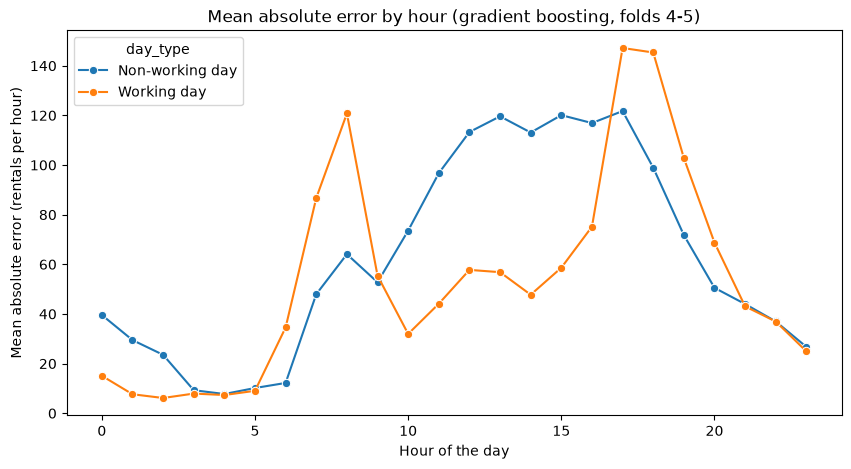

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
by_hour = ana.groupby(['hr', 'day_type'], as_index=False)['abs_error'].mean()

plt.figure(figsize=(10, 5))
sns.lineplot(data=by_hour, x='hr', y='abs_error', hue='day_type', marker='o')
plt.title('Mean absolute error by hour (gradient boosting, folds 4-5)')
plt.xlabel('Hour of the day')
plt.ylabel('Mean absolute error (rentals per hour)')
plt.show()

In [35]:
ana['time_band'] = pd.cut(
    ana['hr'], bins=[-1, 5, 9, 15, 19, 23],
    labels=['Night 0-5', 'Morning 6-9', 'Midday 10-15',
            'Evening 16-19', 'Late evening 20-23'],
)

band_table = ana.groupby(['day_type', 'time_band'], observed=True).agg(
    rows=('cnt', 'size'),
    mean_cnt=('cnt', 'mean'),
    MAE=('abs_error', 'mean'),
    bias=('error', 'mean'),
)
band_table['MAE / mean cnt'] = band_table['MAE'] / band_table['mean_cnt']

print(band_table['rows'].sum())
band_table.round(2)

5085


rows  mean_cnt     MAE   bias  \
day_type        time_band                                           
Non-working day Night 0-5            395     59.70   19.96 -12.86   
                Morning 6-9          264    126.37   44.26   7.56   
                Midday 10-15         396    488.48  106.07 -64.14   
                Evening 16-19        264    439.30  102.34 -50.89   
                Late evening 20-23   264    193.50   39.56 -15.38   
Working day     Night 0-5            874     22.07    8.87  -0.56   
                Morning 6-9          584    379.66   74.38 -60.00   
                Midday 10-15         876    250.22   49.50 -34.03   
                Evening 16-19        584    595.65  117.62 -96.43   
                Late evening 20-23   584    241.08   43.42 -30.15   

                                    MAE / mean cnt  
day_type        time_band                           
Non-working day Night 0-5                     0.33  
                Morning 6-9                   0.35  
                Midday 10-15                  0.22  
                Evening 16-19                 0.23  
                Late evening 20-23            0.20  
Working day     Night 0-5                     0.40  
                Morning 6-9                   0.20  
                Midday 10-15                  0.20  
                Evening 16-19                 0.20  
                Late evening 20-23            0.18

In [36]:
fold_band = ana.groupby(['fold', 'day_type', 'time_band'], observed=True).agg(
    mean_cnt=('cnt', 'mean'),
    MAE=('abs_error', 'mean'),
    bias=('error', 'mean'),
)
fold_band['MAE / mean cnt'] = fold_band['MAE'] / fold_band['mean_cnt']
fold_band['bias / mean cnt'] = fold_band['bias'] / fold_band['mean_cnt']

fold_band[['MAE / mean cnt', 'bias / mean cnt']].unstack('fold').round(2)

MAE / mean cnt       bias / mean cnt      
fold                                            4     5               4     5
day_type        time_band                                                    
Non-working day Night 0-5                    0.34  0.33           -0.21 -0.22
                Morning 6-9                  0.38  0.32           -0.14  0.25
                Midday 10-15                 0.30  0.14           -0.28  0.01
                Evening 16-19                0.30  0.17           -0.27  0.04
                Late evening 20-23           0.23  0.18           -0.16 -0.01
Working day     Night 0-5                    0.43  0.38           -0.06 -0.00
                Morning 6-9                  0.26  0.14           -0.25 -0.08
                Midday 10-15                 0.29  0.11           -0.28 -0.01
                Evening 16-19                0.28  0.12           -0.26 -0.08
                Late evening 20-23           0.24  0.13           -0.19 -0.08

In [37]:
weather_fold = ana.groupby(['weather', 'fold']).agg(
    rows=('cnt', 'size'),
    mean_cnt=('cnt', 'mean'),
    MAE=('abs_error', 'mean'),
    bias=('error', 'mean'),
)
weather_fold['MAE / mean cnt'] = weather_fold['MAE'] / weather_fold['mean_cnt']
weather_fold['bias / mean cnt'] = weather_fold['bias'] / weather_fold['mean_cnt']
weather_fold.round(2)

rows  mean_cnt    MAE   bias  MAE / mean cnt  \
weather     fold                                                 
Clear       4     1729    275.82  75.71 -71.03            0.27   
            5     1863    294.18  38.26  -8.80            0.13   
Mist/Cloudy 4      611    222.85  64.50 -56.73            0.29   
            5      540    273.85  43.57  -8.11            0.16   
Rain/Snow   4      201    128.28  55.98  -4.55            0.44   
            5      141    223.52  79.83 -43.08            0.36   

                  bias / mean cnt  
weather     fold                   
Clear       4               -0.26  
            5               -0.03  
Mist/Cloudy 4               -0.25  
            5               -0.03  
Rain/Snow   4               -0.04  
            5               -0.19

**_5.2 Loss Function_**

Gradient boosting (11 features, target `cnt`) is trained with four loss functions: squared error (current), Poisson, gamma and absolute error. Poisson and gamma use a logarithmic link, so tree contributions multiply, which may carry the growth of demand in 2012 over to periods that are not in the training part. The error analysis showed an almost constant relative error, which is also the structure behind the gamma loss. Folds 4 and 5 are judged separately: a loss is better only if it does not make either of them worse.

In [38]:
def make_boosting_loss(loss):
    def make():
        return HistGradientBoostingRegressor(loss=loss, early_stopping=False, random_state=42)
    return make

loss_names = ['squared_error', 'poisson', 'gamma', 'absolute_error']
loss_preds = {
    loss: cv_predictions(make_boosting_loss(loss), features_tree_v2)
    for loss in loss_names
}

base_mae = loss_preds['squared_error'].groupby('fold')['error'].apply(lambda e: e.abs().mean())
old_mae = feature_preds[v2_name].groupby('fold')['error'].apply(lambda e: e.abs().mean())
print(np.allclose(base_mae.values, old_mae.values))

True


In [39]:
mae_l = variant_table(loss_preds, lambda e: e.abs().mean())
mae_l['diff 4-5 vs squared_error'] = mae_l['mean 4-5'] - mae_l.loc['squared_error', 'mean 4-5']
mae_l.round(2)

fold,1,2,3,4,5,mean 4-5,mean all,diff 4-5 vs squared_error
squared_error,61.27,30.78,56.70,71.46,41.69,56.57,52.38,0.00
poisson,61.01,30.59,56.49,70.16,37.16,53.66,51.08,-2.91
gamma,61.05,31.14,57.53,74.19,45.23,59.71,53.83,3.14
absolute_error,62.22,30.40,56.21,74.22,47.33,60.78,54.08,4.20


In [40]:
rmse_l = variant_table(loss_preds, lambda e: np.sqrt((e ** 2).mean()))
rmse_l['diff 4-5 vs squared_error'] = rmse_l['mean 4-5'] - rmse_l.loc['squared_error', 'mean 4-5']
rmse_l.round(2)

fold,1,2,3,4,5,mean 4-5,mean all,diff 4-5 vs squared_error
squared_error,85.95,48.86,86.11,101.75,62.35,82.05,77.00,0.00
poisson,84.35,48.85,87.60,100.46,58.19,79.32,75.89,-2.73
gamma,87.83,50.32,87.49,105.37,69.34,87.36,80.07,5.30
absolute_error,89.29,48.56,84.29,105.71,72.10,88.91,79.99,6.85


In [41]:
bias_l = variant_table(loss_preds, lambda e: e.mean())
bias_l.round(2)

fold,1,2,3,4,5,mean 4-5,mean all
squared_error,-47.69,-8.35,-30.74,-62.33,-10.55,-36.44,-31.93
poisson,-52.05,-9.66,-35.24,-63.65,-9.89,-36.77,-34.10
gamma,-52.49,-8.94,-38.14,-68.61,-14.63,-41.62,-36.56
absolute_error,-54.38,-4.65,-35.36,-67.44,-18.23,-42.83,-36.01


**_5.3 Hyperparameter Search_**

A random search over 25 parameter combinations is run for gradient boosting with the Poisson loss on the 11 features: learning rate, number of iterations, number of leaves, minimum leaf size and L2 regularization. The default parameters are evaluated in the same way as the reference. A combination is considered better only if it does not make fold 4 or fold 5 worse and gains more than about 1 MAE, because there are only two reliable folds and small differences can be noise. The test set is not used.

In [42]:
import time
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import ParameterSampler

param_distributions = {
    'learning_rate': loguniform(0.03, 0.2),
    'max_iter': randint(100, 601),
    'max_leaf_nodes': randint(15, 64),
    'min_samples_leaf': randint(10, 61),
    'l2_regularization': uniform(0, 10),
}
int_keys = ['max_iter', 'max_leaf_nodes', 'min_samples_leaf']

default_params = {'learning_rate': 0.1, 'max_iter': 100, 'max_leaf_nodes': 31,
                  'min_samples_leaf': 20, 'l2_regularization': 0.0}

sampled = [
    {k: (int(v) if k in int_keys else float(v)) for k, v in p.items()}
    for p in ParameterSampler(param_distributions, n_iter=25, random_state=42)
]
candidates = [default_params] + sampled

def make_boosting_params(params):
    def make():
        return HistGradientBoostingRegressor(
            loss='poisson', early_stopping=False, random_state=42, **params
        )
    return make

rows = []
for i, params in enumerate(candidates):
    start = time.time()
    res = evaluate_cv(make_boosting_params(params), features_tree_v2).set_index('fold')
    rows.append({
        'id': i, **params,
        'MAE_4': res.loc[4, 'MAE'], 'MAE_5': res.loc[5, 'MAE'],
        'RMSE_4': res.loc[4, 'RMSE'], 'RMSE_5': res.loc[5, 'RMSE'],
        'MAE_all': res['MAE'].mean(),
    })
    print(i, round(time.time() - start, 1), 's')

search = pd.DataFrame(rows)

0 1.6 s
1 2.0 s
2 6.4 s
3 6.7 s
4 7.1 s
5 5.1 s
6 6.9 s
7 3.3 s
8 8.0 s
9 3.3 s
10 3.8 s
11 4.0 s
12 9.7 s
13 5.7 s
14 8.8 s
15 5.7 s
16 2.4 s
17 10.7 s
18 4.4 s
19 1.9 s
20 3.4 s
21 2.6 s
22 7.3 s
23 9.7 s
24 1.7 s
25 6.0 s


In [48]:
print(search.loc[0, ['MAE_4', 'MAE_5']].round(2).tolist())

[70.16, 37.16]


In [50]:
search['MAE_4-5'] = (search['MAE_4'] + search['MAE_5']) / 2
search['RMSE_4-5'] = (search['RMSE_4'] + search['RMSE_5']) / 2
search['dMAE_4'] = search['MAE_4'] - search.loc[0, 'MAE_4']
search['dMAE_5'] = search['MAE_5'] - search.loc[0, 'MAE_5']

cols = ['id', 'learning_rate', 'max_iter', 'max_leaf_nodes', 'min_samples_leaf',
        'l2_regularization', 'MAE_4', 'MAE_5', 'MAE_4-5', 'RMSE_4-5',
        'dMAE_4', 'dMAE_5', 'MAE_all']

print(search.shape)
print(search.sort_values('MAE_4-5')[cols].head(8).round(3).to_string(index=False))

(26, 15)
 id  learning_rate  max_iter  max_leaf_nodes  min_samples_leaf  l2_regularization  MAE_4  MAE_5  MAE_4-5  RMSE_4-5  dMAE_4  dMAE_5  MAE_all
  6          0.064       575              30                24              5.248 64.999 34.543   49.771    74.362  -5.157  -2.618   48.925
 20          0.120       388              19                51              7.069 64.387 36.064   50.225    75.183  -5.769  -1.098   48.677
 25          0.130       458              41                18              5.613 64.301 36.800   50.550    75.912  -5.854  -0.362   49.875
 24          0.190       230              15                14              3.829 66.126 35.245   50.685    75.815  -4.029  -1.917   48.387
  2          0.040       430              25                33              1.560 66.090 35.865   50.978    75.783  -4.065  -1.296   49.446
 10          0.110       466              21                53              0.977 66.436 36.219   51.328    76.693  -3.719  -0.942   49.211
  5        

In [51]:
tuned_params = candidates[6]
print(tuned_params)

tuned_preds = {
    'poisson default': cv_predictions(make_boosting_params(default_params), features_tree_v2),
    'poisson tuned (id 6)': cv_predictions(make_boosting_params(tuned_params), features_tree_v2),
}

better_both = ((search['dMAE_4'] < 0) & (search['dMAE_5'] < 0)).sum()
print('candidates better than default on both folds:', better_both, 'of', len(search) - 1)

metrics = [
    ('MAE', lambda e: e.abs().mean()),
    ('RMSE', lambda e: np.sqrt((e ** 2).mean())),
    ('bias', lambda e: e.mean()),
]
for name, f in metrics:
    print(name)
    print(variant_table(tuned_preds, f).round(2).to_string())

{'l2_regularization': 5.2477466025838915, 'learning_rate': 0.06405753233449049, 'max_iter': 575, 'max_leaf_nodes': 30, 'min_samples_leaf': 24}
candidates better than default on both folds: 13 of 25
MAE
fold                      1      2      3      4      5  mean 4-5  mean all
poisson default       61.01  30.59  56.49  70.16  37.16     53.66     51.08
poisson tuned (id 6)  56.79  31.33  56.97  65.00  34.54     49.77     48.93
RMSE
fold                      1      2      3       4      5  mean 4-5  mean all
poisson default       84.35  48.85  87.60  100.46  58.19     79.32     75.89
poisson tuned (id 6)  79.16  49.77  87.78   93.15  55.57     74.36     73.09
bias
fold                      1      2      3      4      5  mean 4-5  mean all
poisson default      -52.05  -9.66 -35.24 -63.65  -9.89    -36.77    -34.10
poisson tuned (id 6) -49.42 -11.27 -35.90 -58.35 -10.71    -34.53    -33.13


Hyperparameter search (25 random combinations, gradient boosting with Poisson loss, 11 features): the best parameters (learning rate 0.064, 575 iterations, 30 leaves, minimum leaf size 24, L2 regularization 5.25) lowered MAE from 70.2 to 65.0 on fold 4 and from 37.2 to 34.5 on fold 5 (RMSE mean of the two 79.3 -> 74.4), and are slightly worse on folds 2 and 3 (by less than 1 MAE). 13 of 25 combinations beat the defaults on both folds. The gain on fold 4 comes mostly from less underestimation, which still makes up most of its error.

**_5.4 Ensemble Check_**

We check whether averaging two models helps: the tuned gradient boosting (Poisson loss) and a Random Forest, both on the 11 features. The ensemble is used only if it beats the tuned gradient boosting alone on both fold 4 and fold 5 by more than about 1 MAE, because it would make the final model and the API more complex.

In [52]:
rf_preds = cv_predictions(make_forest, features_tree_v2)
gb_preds = tuned_preds['poisson tuned (id 6)']

print((rf_preds.index == gb_preds.index).all())

ens_preds = gb_preds.copy()
ens_preds['pred'] = (gb_preds['pred'] + rf_preds['pred']) / 2
ens_preds['error'] = ens_preds['pred'] - ens_preds['cnt']

ens_dict = {
    'gradient boosting (tuned)': gb_preds,
    'random forest (11 features)': rf_preds,
    'average of the two': ens_preds,
}

for name, f in metrics:
    print(name)
    print(variant_table(ens_dict, f).round(2).to_string())

True
MAE
fold                             1      2      3      4      5  mean 4-5  mean all
gradient boosting (tuned)    56.79  31.33  56.97  65.00  34.54     49.77     48.93
random forest (11 features)  62.65  33.22  56.76  76.80  42.72     59.76     54.43
average of the two           59.27  30.65  56.14  70.52  36.93     53.72     50.70
RMSE
fold                             1      2      3       4      5  mean 4-5  mean all
gradient boosting (tuned)    79.16  49.77  87.78   93.15  55.57     74.36     73.09
random forest (11 features)  87.98  54.48  86.21  108.56  68.57     88.56     81.16
average of the two           82.31  49.27  86.20   99.95  58.82     79.39     75.31
bias
fold                             1      2      3      4      5  mean 4-5  mean all
gradient boosting (tuned)   -49.42 -11.27 -35.90 -58.35 -10.71    -34.53    -33.13
random forest (11 features) -48.75  -0.96 -29.57 -67.51  -3.28    -35.40    -30.02
average of the two          -49.09  -6.12 -32.73 -62.93  -7.00  

### 6. Final Model and Test Evaluation

**_6.1 Test Evaluation_**

The final model is gradient boosting with the Poisson loss on 11 features with the parameters chosen in 5.3. It is trained on the whole training set (2011-01-01 to 2012-09-30) and evaluated once on the test set (2012-10-01 to 2012-12-31). For comparison, the three reference models are trained and evaluated in the same way. The test set was not used for any choice made so far, and the model is not changed after this evaluation. The test covers only three colder months of 2012, so the results may not reflect other seasons.

In [53]:
final_models = {
    'constant': (make_constant, ['hr_workingday'], 'cnt'),
    'hr_workingday mean': (make_hr_workingday, ['hr_workingday'], 'cnt'),
    'linear regression (sqrt target)': (make_linear, features_linear, 'sqrt'),
    'gradient boosting (final)': (make_boosting_params(tuned_params), features_tree_v2, 'cnt'),
}

def fit_predict_test(make_model, features, target_kind):
    model = with_target(make_model(), target_kind)
    model.fit(train_df[features], train_df['cnt'])
    return model.predict(test_df[features])

y_test_true = test_df['cnt'].values
print(len(train_df), len(test_df), round(y_test_true.mean(), 2))

rows = []
for name, (mk, feats, kind) in final_models.items():
    err = fit_predict_test(mk, feats, kind) - y_test_true
    rows.append({
        'model': name,
        'MAE': np.abs(err).mean(),
        'RMSE': np.sqrt((err ** 2).mean()),
        'bias': err.mean(),
    })

test_results = pd.DataFrame(rows).set_index('model')
test_results['MAE / mean cnt'] = test_results['MAE'] / y_test_true.mean()
print(test_results.round(3).to_string())

15211 2168 219.2
                                     MAE     RMSE    bias  MAE / mean cnt
model                                                                    
constant                         156.868  204.428 -33.971           0.716
hr_workingday mean                79.950  119.589 -34.541           0.365
linear regression (sqrt target)   67.087   98.720 -33.505           0.306
gradient boosting (final)         40.425   64.525 -14.563           0.184


**_6.2 Error Breakdown on the Test Set_**

For the final model, the test errors are broken down by time of day, day type and weather. This is for reporting only: the model is not changed after the test evaluation.

In [54]:
gb_test_pred = fit_predict_test(*final_models['gradient boosting (final)'])

test_ana = test_df[['hr', 'workingday', 'weathersit', 'cnt']].copy()
test_ana['pred'] = gb_test_pred
test_ana['error'] = test_ana['pred'] - test_ana['cnt']
test_ana['abs_error'] = test_ana['error'].abs()
print(round(test_ana['abs_error'].mean(), 3))

test_ana['day_type'] = test_ana['workingday'].map({0: 'Non-working day', 1: 'Working day'})
test_ana['weather'] = test_ana['weathersit'].map({1: 'Clear', 2: 'Mist/Cloudy', 3: 'Rain/Snow'})
test_ana['time_band'] = pd.cut(
    test_ana['hr'], bins=[-1, 5, 9, 15, 19, 23],
    labels=['Night 0-5', 'Morning 6-9', 'Midday 10-15',
            'Evening 16-19', 'Late evening 20-23'],
)

def breakdown(keys):
    table = test_ana.groupby(keys, observed=True).agg(
        rows=('cnt', 'size'), mean_cnt=('cnt', 'mean'),
        MAE=('abs_error', 'mean'), bias=('error', 'mean'),
    )
    table['MAE / mean cnt'] = table['MAE'] / table['mean_cnt']
    table['bias / mean cnt'] = table['bias'] / table['mean_cnt']
    return table.round(2)

print(breakdown(['day_type', 'time_band']).to_string())
print(breakdown(['weather']).to_string())

40.425
                                    rows  mean_cnt    MAE   bias  MAE / mean cnt  bias / mean cnt
day_type        time_band                                                                        
Non-working day Night 0-5            179     46.42  14.14  -6.47            0.30            -0.14
                Morning 6-9          120    103.63  30.27 -15.43            0.29            -0.15
                Midday 10-15         180    384.36  65.68 -15.53            0.17            -0.04
                Evening 16-19        120    301.27  60.41  -5.12            0.20            -0.02
                Late evening 20-23   120    119.49  23.28  -5.99            0.19            -0.05
Working day     Night 0-5            358     19.39   6.22  -2.58            0.32            -0.13
                Morning 6-9          240    349.18  67.72 -28.75            0.19            -0.08
                Midday 10-15         363    232.56  34.39 -11.79            0.15            -0.05
             

**_6.3 Final Model for the API_**

The final model (gradient boosting, Poisson loss, 11 features, parameters from 5.3) is refitted on all available data (training and test, 17,379 rows) and saved for the API together with a configuration file. A plain `HistGradientBoostingRegressor` is saved without the target-transformation wrapper; it is first checked that it gives exactly the same test predictions as the model evaluated in 6.1. The reported quality is the test result of 6.1 (model trained on the training part only).

In [55]:
plain_model = HistGradientBoostingRegressor(
    loss='poisson', early_stopping=False, random_state=42, **tuned_params
)
plain_model.fit(train_df[features_tree_v2], train_df['cnt'])
plain_pred = plain_model.predict(test_df[features_tree_v2])

print(np.allclose(plain_pred, gb_test_pred))
print(round(np.abs(plain_pred - test_df['cnt'].values).mean(), 3), plain_pred.min() > 0)

True
40.425 True


In [56]:
import json, os
import sklearn

full_df = pd.concat([train_df, test_df], ignore_index=True)
print(len(full_df), full_df[features_tree_v2].isna().sum().sum())

final_model = HistGradientBoostingRegressor(
    loss='poisson', early_stopping=False, random_state=42, **tuned_params
)
final_model.fit(full_df[features_tree_v2], full_df['cnt'])

os.makedirs('../models', exist_ok=True)
joblib.dump(final_model, '../models/bike_demand_model.joblib')

config = {
    'features': features_tree_v2,
    'params': {'loss': 'poisson', 'early_stopping': False, 'random_state': 42, **tuned_params},
    'target': 'cnt',
    'train_period': [str(full_df['dteday'].min().date()), str(full_df['dteday'].max().date())],
    'n_rows': int(len(full_df)),
    'sklearn_version': sklearn.__version__,
    'note': 'weathersit 4 is merged into 3 before prediction',
}
with open('../models/model_config.json', 'w') as f:
    json.dump(config, f, indent=2)

17379 0


In [57]:
loaded = joblib.load('../models/bike_demand_model.joblib')
print(np.allclose(loaded.predict(full_df[features_tree_v2]),
                  final_model.predict(full_df[features_tree_v2])))
print(open('../models/model_config.json').read())

True
{
  "features": [
    "season",
    "yr",
    "mnth",
    "hr",
    "holiday",
    "weekday",
    "workingday",
    "weathersit",
    "temp",
    "hum",
    "windspeed"
  ],
  "params": {
    "loss": "poisson",
    "early_stopping": false,
    "random_state": 42,
    "l2_regularization": 5.2477466025838915,
    "learning_rate": 0.06405753233449049,
    "max_iter": 575,
    "max_leaf_nodes": 30,
    "min_samples_leaf": 24
  },
  "target": "cnt",
  "train_period": [
    "2011-01-01",
    "2012-12-31"
  ],
  "n_rows": 17379,
  "sklearn_version": "1.9.1",
  "note": "weathersit 4 is merged into 3 before prediction"
}


### 7. Baseline and Model Comparison Summary

**Evaluation setup.** MAE and RMSE on the original `cnt` scale, computed separately for 5 time-based CV folds. Folds 4 and 5 are the main ones: folds 1-3 train on 2011 only and are affected by the shift in demand level in 2012. The test set was used once, at the end.

**Reference models** (mean over 5 folds, MAE / RMSE): constant 146.3 / 190.7, mean by hour and day type 90.5 / 124.5, linear regression 73.8 / 97.4.

**Tree models on 13 features** (mean over 5 folds, MAE / RMSE): decision tree 60.5 / 91.5, random forest 54.4 / 81.1, gradient boosting 52.1 / 76.8.

**Decisions.**
- Target: raw `cnt` for tree models, `sqrt(cnt)` for linear regression; `log1p` was unstable.
- `yr` is essential (without it MAE on folds 4-5 rises from 56.3 to 95.9).
- `atemp` and `windspeed_zero` were removed: 11 features remain.
- Poisson loss improved MAE on folds 4-5 from 56.6 to 53.7.
- Random search over 25 combinations (learning rate 0.064, 575 iterations, 30 leaves, minimum leaf size 24, L2 5.25) lowered it to 49.8 (RMSE 79.3 -> 74.4).
- An average with a random forest was worse, so no ensemble is used.

**Findings.** The main source of error is the shift in demand level in 2012: on fold 4 the model underestimates daytime demand by about 25-28% and nearly all of its error is this bias, while on fold 5 the daytime error is about 11-18%. Nights and rain/snow have the highest relative errors.

**Test result** (2012-10-01 to 2012-12-31): MAE 40.4, RMSE 64.5 (about 18% of mean demand), bias -14.6, versus 67.1 / 98.7 for linear regression, 80.0 / 119.6 for the mean by hour and day type and 156.9 / 204.4 for the constant.

**Limitations.**
- The test covers only three colder months of one year.
- `yr` is 0 or 1, so the model cannot be trusted for later years.
- There are only two reliable CV folds; differences below about 1 MAE were not treated as real.
- Improvements of the linear model (Ridge, year-by-month interaction, non-linear temperature) were not explored.
- The reasons for the growth in 2012 and for the lower quality at night are unknown.
- The final model is refitted on all data, so it has no independent evaluation; the reported quality is the test result of the model trained on the training part.

**Saved files.** `models/bike_demand_model.joblib` and `models/model_config.json`. Input: 11 features in a fixed order, with `weathersit` 4 merged into 3.